In [1]:
from collections import Counter

import numpy
import seaborn

from matplotlib import pyplot

from searchlight.models.simulens import SimuLens
# from searchlight.models.deprecated.tree import XGBFilter
# from searchlight.models.deprecated.upsilon import UpsilonFilter
from searchlight.lightcurves import LC_VALIDATION_PATH

In [2]:
LABELS = sorted(
    path.name for path in LC_VALIDATION_PATH.iterdir() if path.is_dir()
)

In [3]:
def classify_validation_folders(model):
    validation_results = {
        label: model.classify_folder(LC_VALIDATION_PATH / label)
        for label in LABELS
    }
    confusion_matrix = numpy.array([
        [
            Counter(v[0] for v in validation_results[label].values())[predicted_label]
            for predicted_label in LABELS
        ]
        for label in LABELS
    ])
    return confusion_matrix

def plot_confusion(confusion_matrix, title=None):
    pyplot.figure(figsize=(8, 6))
    seaborn.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues', 
                xticklabels=LABELS, yticklabels=LABELS)
    pyplot.ylabel('True Label')
    pyplot.xlabel('Predicted Label')
    if title is not None:
        pyplot.title(title)
    pyplot.show()

In [4]:
# t = XGBFilter()
# t_results, t_confusion = classify_validation_folders(t)
# plot_confusion(t_confusion, "XGBoost Confusion")

In [5]:
# u = UpsilonFilter()
# u_results, u_confusion = classify_validation_folders(u)
# plot_confusion(u_confusion, "UPSILON-T Confusion")

Classify:   0%|          | 0/300 [00:00<?, ?it/s]

Classify:   0%|          | 0/100 [00:00<?, ?it/s]

Classify:   0%|          | 0/145 [00:00<?, ?it/s]

Classify:   0%|          | 0/242 [00:00<?, ?it/s]

Classify:   0%|          | 0/161 [00:00<?, ?it/s]

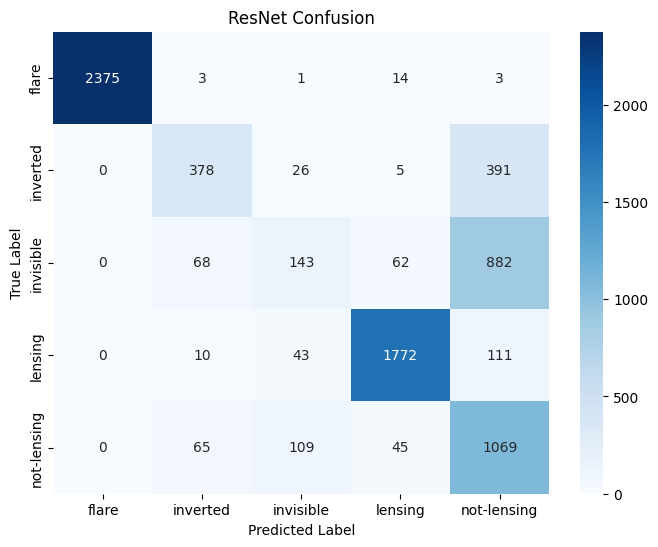

In [6]:
r = SimuLens(loader_workers=0) # loader_workers=0 to avoid multiprocessing bug with Jupyter
r_confusion = classify_validation_folders(r)
plot_confusion(r_confusion, "ResNet Confusion")